In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT_DIR / "data" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

In [10]:
df = pd.read_csv(DATA_PATH)
df.head(3)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [6]:
print("Shape:", df.shape)
print("\nChurn distribution:")
print(df["Churn"].value_counts(dropna=False))
print("Churn rate (%):", round((df["Churn"] == "Yes").mean() * 100, 2))

Shape: (7043, 21)

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn rate (%): 26.54


In [ ]:
total_charges_num = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("\nBlank/non-numeric TotalCharges rows:", int(total_charges_num.isna().sum()))
print("Rows with tenure == 0:", int((df["tenure"] == 0).sum()))

print("\nNumeric summary:")
numeric_df = df.assign(TotalCharges_num=total_charges_num)[
    ["tenure", "MonthlyCharges", "TotalCharges_num", "SeniorCitizen"]
]
print(numeric_df.describe().round(2))



Blank/non-numeric TotalCharges rows: 11
Rows with tenure == 0: 11

Numeric summary:
        tenure  MonthlyCharges  TotalCharges_num  SeniorCitizen
count  7043.00         7043.00           7032.00        7043.00
mean     32.37           64.76           2283.30           0.16
std      24.56           30.09           2266.77           0.37
min       0.00           18.25             18.80           0.00
25%       9.00           35.50            401.45           0.00
50%      29.00           70.35           1397.48           0.00
75%      55.00           89.85           3794.74           0.00
max      72.00          118.75           8684.80           1.00


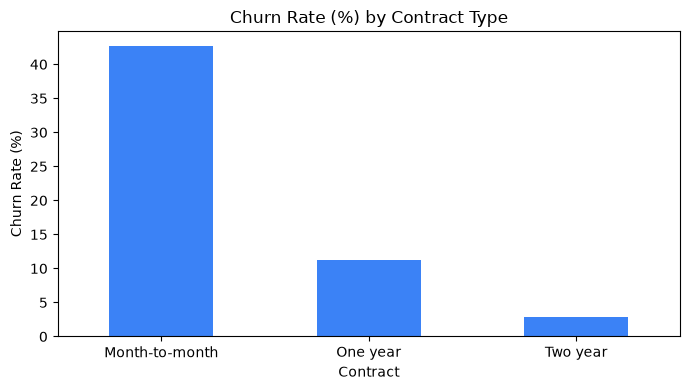

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
churn_by_contract = (
    df.groupby("Contract")["Churn"]
    .apply(lambda s: (s == "Yes").mean() * 100)
    .sort_values(ascending=False)
)
churn_by_contract.plot(kind="bar", ax=ax, color="#3b82f6")
ax.set_title("Churn Rate (%) by Contract Type")
ax.set_ylabel("Churn Rate (%)")
ax.set_xlabel("Contract")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()